In [2]:
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.read_csv("../data/processed/sales_features.csv")

print("Dataset shape:", sales.shape)
print("\nFirst five rows:")
display(sales.head())

print("\nColumn names:")
print(sales.columns.tolist())

Dataset shape: (10035, 28)

First five rows:


,transaction_id,transaction_datetime,transaction_date,line_number,store_id,store_name,county,town,customer_id,product_id,...,net_sales_kes,payment_method,year,month,month_name,day_of_week,day_of_week_number,week_number,is_weekend,transaction_value_kes
0,TXN004795,2025-01-01 07:19:00,2025-01-01,1,ST006,Jirani Mart - Ruiru,Kiambu,Ruiru,CUST00214,PR002,...,286.55,Cash,2025,1,January,Wednesday,2,1,False,446.29
1,TXN004795,2025-01-01 07:19:00,2025-01-01,2,ST006,Jirani Mart - Ruiru,Kiambu,Ruiru,CUST00214,PR016,...,159.74,Cash,2025,1,January,Wednesday,2,1,False,446.29
2,TXN003214,2025-01-01 10:08:00,2025-01-01,1,ST018,Jirani Mart - Nyeri Town,Nyeri,Nyeri Town,CUST00091,PR010,...,1461.54,Cash,2025,1,January,Wednesday,2,1,False,2450.80
3,TXN003214,2025-01-01 10:08:00,2025-01-01,2,ST018,Jirani Mart - Nyeri Town,Nyeri,Nyeri Town,CUST00091,PR009,...,989.26,Cash,2025,1,January,Wednesday,2,1,False,2450.80
4,TXN003375,2025-01-01 11:39:00,2025-01-01,1,ST012,Jirani Mart - Naivasha,Nakuru,Naivasha,CUST00515,PR014,...,181.90,Debit/Credit Card,2025,1,January,Wednesday,2,1,False,967.50



Column names:
['transaction_id', 'transaction_datetime', 'transaction_date', 'line_number', 'store_id', 'store_name', 'county', 'town', 'customer_id', 'product_id', 'product_name', 'product_category', 'quantity', 'unit_price_kes', 'gross_sales_kes', 'promotion', 'discount_rate', 'discount_amount_kes', 'net_sales_kes', 'payment_method', 'year', 'month', 'month_name', 'day_of_week', 'day_of_week_number', 'week_number', 'is_weekend', 'transaction_value_kes']


,month,net_sales_kes,month_name
0,1,532714.50,January
1,2,500416.95,February
2,3,549452.52,March
3,4,578647.10,April
4,5,634194.33,May
5,6,558743.37,June
6,7,577331.44,July
7,8,570443.21,August
8,9,503229.57,September
9,10,596014.90,October


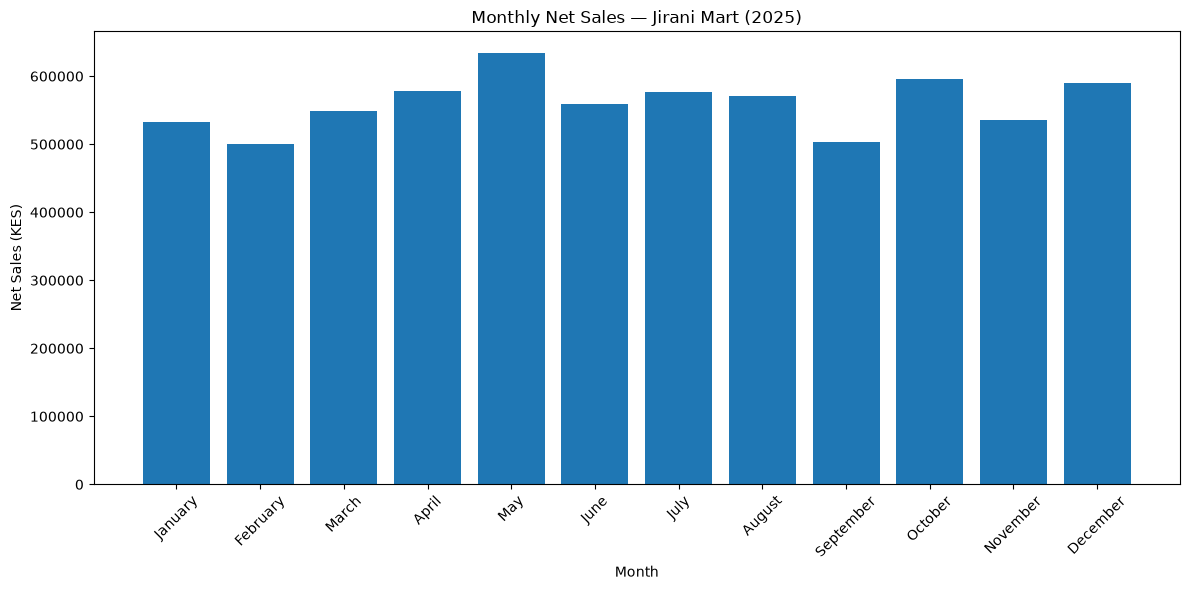

In [3]:
# Convert the date column to datetime
sales["transaction_date"] = pd.to_datetime(sales["transaction_date"])

# Calculate total net sales by month
monthly_sales = (
    sales.groupby("month")["net_sales_kes"]
    .sum()
    .reset_index()
)

# Add readable month names
monthly_sales["month_name"] = monthly_sales["month"].apply(
    lambda x: pd.Timestamp(month=x, day=1, year=2025).strftime("%B")
)

# Display the results
display(monthly_sales)

# Plot monthly sales
plt.figure(figsize=(12, 6))
plt.bar(monthly_sales["month_name"], monthly_sales["net_sales_kes"])
plt.title("Monthly Net Sales — Jirani Mart (2025)")
plt.xlabel("Month")
plt.ylabel("Net Sales (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Finding 1: Monthly Sales Trends

Monthly net sales fluctuated throughout 2025 rather than following a consistent upward trend. May recorded the highest sales at KES 634,194.33, while February had the lowest at KES 500,416.95. Sales increased from February through May, declined in June, and recovered during several later months, including October and December. Further analysis is needed to determine whether these changes are associated with product demand, promotions, customer behaviour, or other factors.

,county,net_sales_kes
0,Nairobi,1523813.42
1,Kiambu,1212042.13
2,Mombasa,1039907.88
3,Machakos,760323.76
4,Kisumu,740793.13
5,Nakuru,674001.33
6,Nyeri,409932.51
7,Uasin Gishu,365473.75


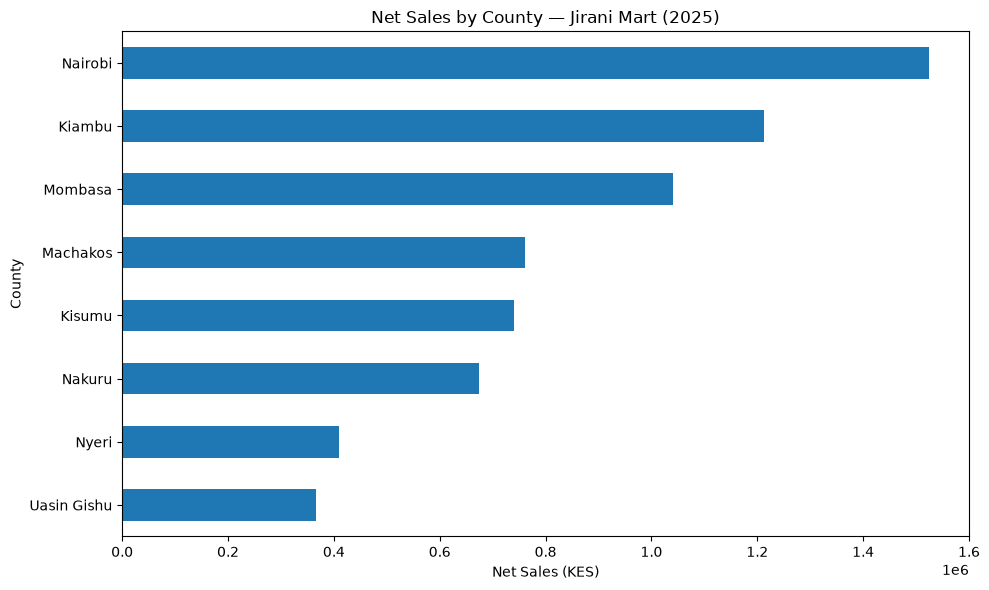

In [4]:
#Which counties generate the most sales?
county_sales = (
    sales.groupby("county")["net_sales_kes"]
    .sum()
    .sort_values(ascending=False)
)

display(county_sales.reset_index())

plt.figure(figsize=(10, 6))
county_sales.sort_values().plot(kind="barh")
plt.title("Net Sales by County — Jirani Mart (2025)")
plt.xlabel("Net Sales (KES)")
plt.ylabel("County")
plt.tight_layout()
plt.show()

### Finding 2: Sales Performance by County

The county analysis shows that Nairobi generated the highest total net sales in 2025, at KES 1,523,813.42. Kiambu followed with KES 1,212,042.13, while Mombasa recorded KES 1,039,907.88. Uasin Gishu had the lowest total net sales at KES 365,473.75. These differences indicate that sales contributions vary across the counties in which Jirani Mart operates. However, total sales alone do not establish which county performs best per store, since the number of stores and transactions may differ.

,product_category,net_sales_kes
0,Home Essentials,1462794.19
1,Electronics & Accessories,1233373.93
2,Food & Pantry,1211095.79
3,Personal Care,701307.71
4,Dairy & Chilled,628331.72
5,Household,549727.91
6,Beverages,512404.54
7,Stationery,362095.32
8,Bakery,65156.80


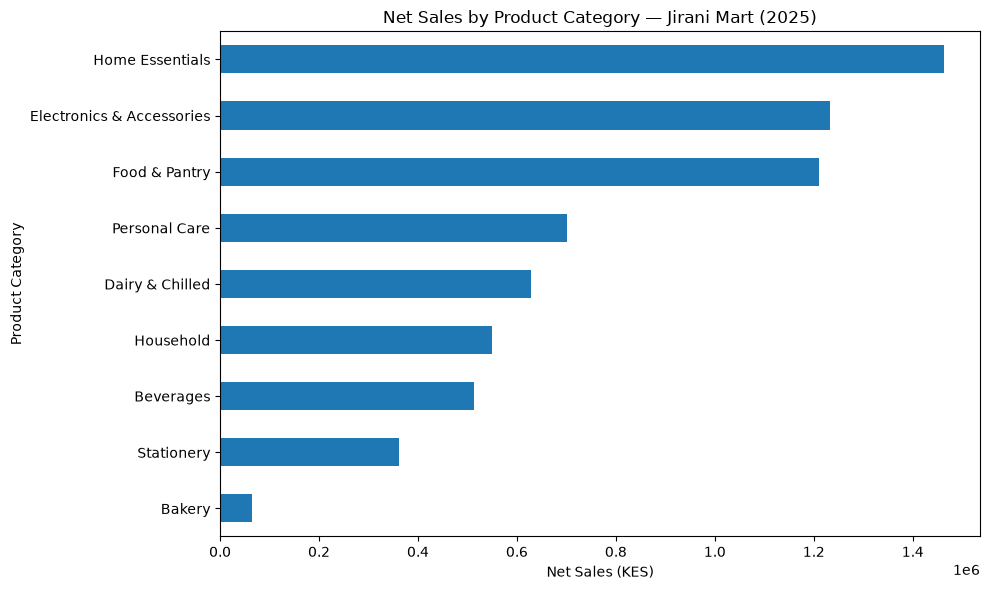

In [5]:
#Analyse product categories
category_sales = (
    sales.groupby("product_category")["net_sales_kes"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales.reset_index())

plt.figure(figsize=(10, 6))
category_sales.sort_values().plot(kind="barh")
plt.title("Net Sales by Product Category — Jirani Mart (2025)")
plt.xlabel("Net Sales (KES)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Finding 3: Sales Performance by Product Category

Home Essentials generated the highest net sales in 2025, contributing KES 1,462,794.19. Electronics & Accessories followed at KES 1,233,373.93, while Food & Pantry recorded KES 1,211,095.79. Bakery had the lowest sales at KES 65,156.80. This indicates that the categories contribute differently to overall revenue. Jirani Mart could investigate the products, pricing, stock availability and customer demand within the lower-performing categories before deciding whether changes are needed.

,store_id,store_name,net_sales_kes
0,ST007,Jirani Mart - Kiambu Town,415539.97
1,ST004,Jirani Mart - Embakasi,413271.16
2,ST018,Jirani Mart - Nyeri Town,409932.51
3,ST006,Jirani Mart - Ruiru,409411.04
4,ST003,Jirani Mart - Eastleigh,401114.88
5,ST017,Jirani Mart - Athi River,397697.84
6,ST013,Jirani Mart - Kisumu CBD,391852.16
7,ST005,Jirani Mart - Thika,387091.12
8,ST009,Jirani Mart - Likoni,367165.02
9,ST015,Jirani Mart - Eldoret Town,365473.75


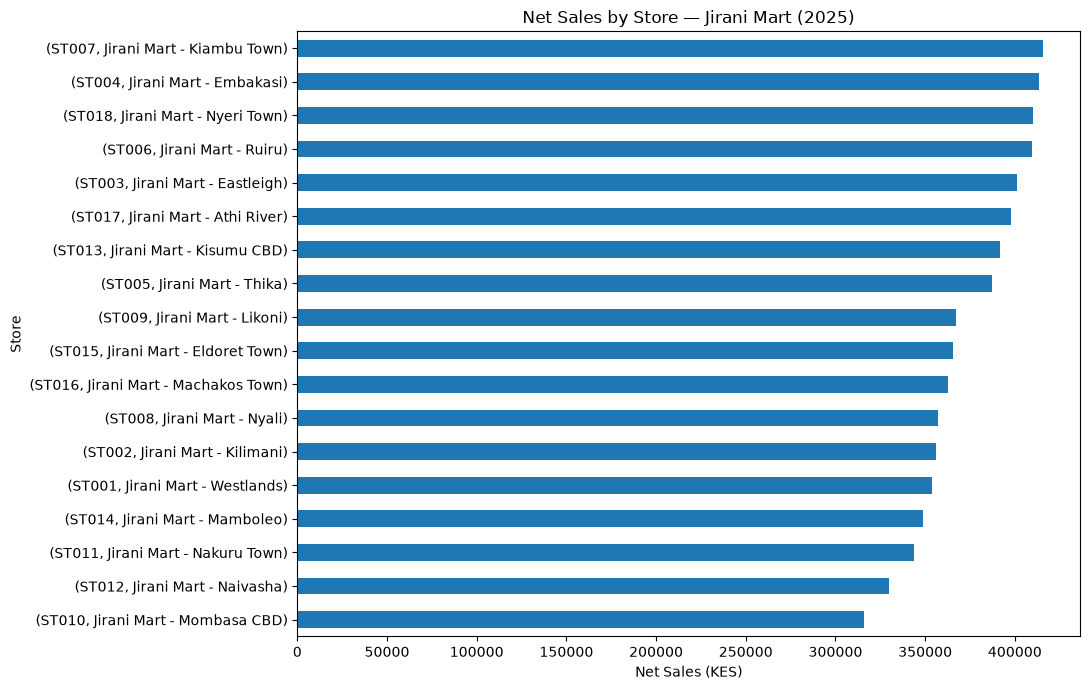

In [6]:
#Which stores generate the most sales?
store_sales = (
    sales.groupby(["store_id", "store_name"])["net_sales_kes"]
    .sum()
    .sort_values(ascending=False)
)

display(store_sales.reset_index())

plt.figure(figsize=(11, 7))
store_sales.sort_values().plot(kind="barh")
plt.title("Net Sales by Store — Jirani Mart (2025)")
plt.xlabel("Net Sales (KES)")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

### Finding 4: Sales Performance by Store

Kiambu Town (ST007) recorded the highest net sales among the 18 stores, at KES 415,539.97. Embakasi (ST004) followed closely at KES 413,271.16, while Mombasa CBD (ST010) recorded the lowest sales at KES 315,831.69. The difference between the highest- and lowest-performing stores was KES 99,708.28. This suggests that sales contributions vary across outlets. Further analysis of customer traffic, transaction volumes, product availability and average transaction value could help explain these differences.

,sum,mean,count
customer_segment,,,
Everyday,3082432.16,5804.956987,531
Value Seeker,1803283.96,5893.084837,306
Loyal,1409029.59,5525.606235,255
Premium,431542.20,5137.407143,84


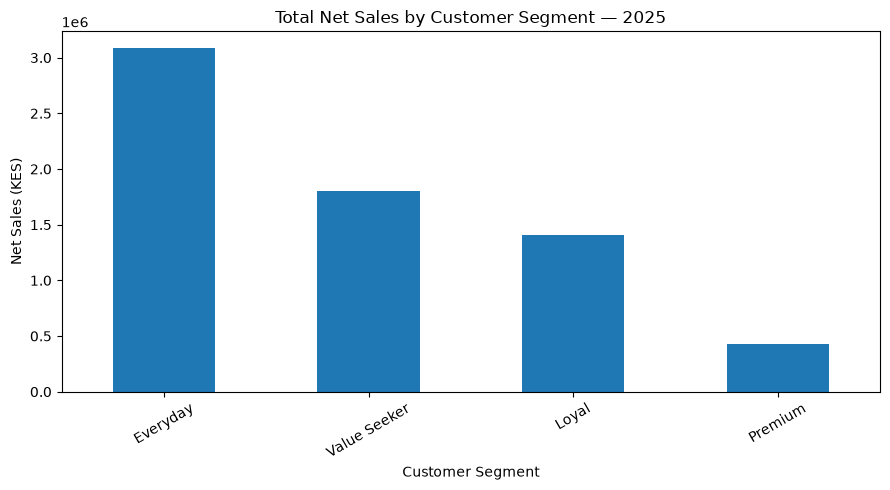

In [7]:
#customer segmentation based on total sales
segment_sales = (
    sales.groupby("customer_id")["net_sales_kes"]
    .sum()
    .reset_index()
    .merge(
        pd.read_csv("../data/processed/customers.csv"),
        on="customer_id",
        how="left"
    )
)

segment_summary = (
    segment_sales.groupby("customer_segment")["net_sales_kes"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

display(segment_summary)

plt.figure(figsize=(9, 5))
segment_summary["sum"].plot(kind="bar")
plt.title("Total Net Sales by Customer Segment — 2025")
plt.xlabel("Customer Segment")
plt.ylabel("Net Sales (KES)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Finding 5: Sales by Customer Segment

The Everyday customer segment generated the highest total net sales in 2025, at KES 3,082,432.16, followed by Value Seeker at KES 1,803,283.96 and Loyal customers at KES 1,409,029.59. Premium customers contributed the lowest total, at KES 431,542.20. Everyday customers also represented the largest group, with 531 customers, compared with 84 Premium customers. These results suggest that customer numbers may influence total segment sales. Average spending and purchase frequency should also be considered before deciding which segment is most valuable to the business.

,day_type,total_net_sales,total_quantity,sales_lines,unique_transactions
0,Weekday,4842862.78,15459,7188,3584
1,Weekend,1883425.13,6178,2847,1416


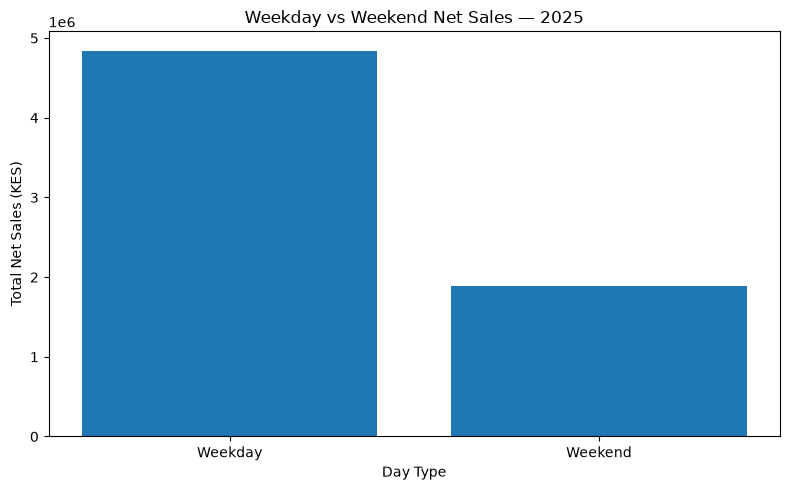

In [8]:
#Compare weekday and weekend sales

# Compare sales on weekdays and weekends
weekend_summary = (
    sales.groupby("is_weekend")
    .agg(
        total_net_sales=("net_sales_kes", "sum"),
        total_quantity=("quantity", "sum"),
        sales_lines=("transaction_id", "count"),
        unique_transactions=("transaction_id", "nunique")
    )
    .reset_index()
)

weekend_summary["day_type"] = weekend_summary["is_weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

display(weekend_summary[[
    "day_type",
    "total_net_sales",
    "total_quantity",
    "sales_lines",
    "unique_transactions"
]])

# Visualise total net sales
plt.figure(figsize=(8, 5))
plt.bar(
    weekend_summary["day_type"],
    weekend_summary["total_net_sales"]
)
plt.title("Weekday vs Weekend Net Sales — 2025")
plt.xlabel("Day Type")
plt.ylabel("Total Net Sales (KES)")
plt.tight_layout()
plt.show()


### Finding 6: Weekday and Weekend Sales Patterns

Weekdays generated KES 4,842,862.78 in net sales across 3,584 unique transactions, while weekends generated KES 1,883,425.13 across 1,416 unique transactions. Weekday sales represented approximately 72% of the total recorded net sales. Weekdays also accounted for more transactions. However, these totals combine five weekdays and two weekend days per week, so average daily sales and transaction values should be compared before concluding that one day type performs better.

,day_type,average_daily_sales,number_of_days
0,Weekday,18555.029808,261
1,Weekend,18109.857019,104


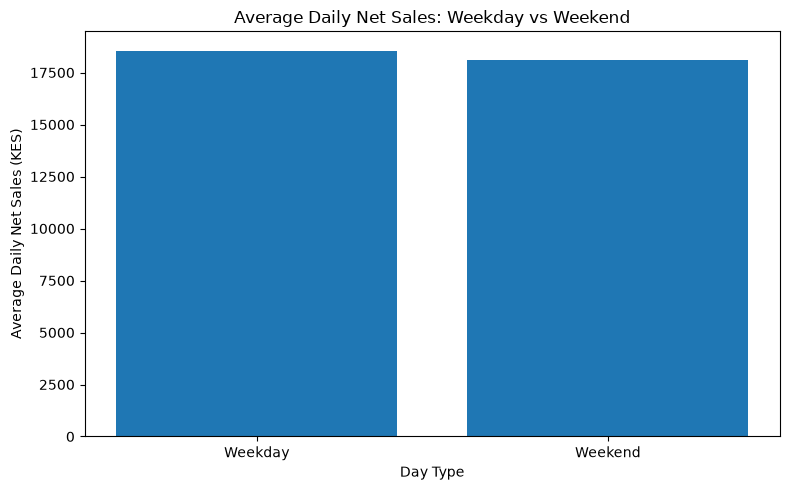

In [9]:

# Count distinct calendar dates in each day type
daily_sales = (
    sales.groupby(["transaction_date", "is_weekend"])["net_sales_kes"]
    .sum()
    .reset_index()
)

daily_summary = (
    daily_sales.groupby("is_weekend")
    .agg(
        average_daily_sales=("net_sales_kes", "mean"),
        number_of_days=("transaction_date", "nunique")
    )
    .reset_index()
)

daily_summary["day_type"] = daily_summary["is_weekend"].map({
    False: "Weekday",
    True: "Weekend"
})

display(daily_summary[[
    "day_type", "average_daily_sales", "number_of_days"
]])

plt.figure(figsize=(8, 5))
plt.bar(
    daily_summary["day_type"],
    daily_summary["average_daily_sales"]
)
plt.title("Average Daily Net Sales: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Net Sales (KES)")
plt.tight_layout()
plt.show()


### Finding 7: Average Daily Sales by Day Type

After accounting for the number of calendar days, average daily net sales were KES 18,555.03 on weekdays and KES 18,109.86 on weekends. Weekday daily sales were approximately KES 445.17 higher, a difference of about 2.5%. This suggests that average daily sales were relatively similar across the two day types, despite weekdays contributing much higher total sales. Further analysis would be needed to determine whether the difference is consistent or statistically meaningful.

,average_daily_sales_kes,total_sales_kes,number_of_days
day_of_week,,,
Monday,16891.064423,878335.35,52
Tuesday,19057.070385,990967.66,52
Wednesday,18712.886792,991783.00,53
Thursday,19009.250577,988481.03,52
Friday,19101.841154,993295.74,52
Saturday,18152.478846,943928.90,52
Sunday,18067.235192,939496.23,52


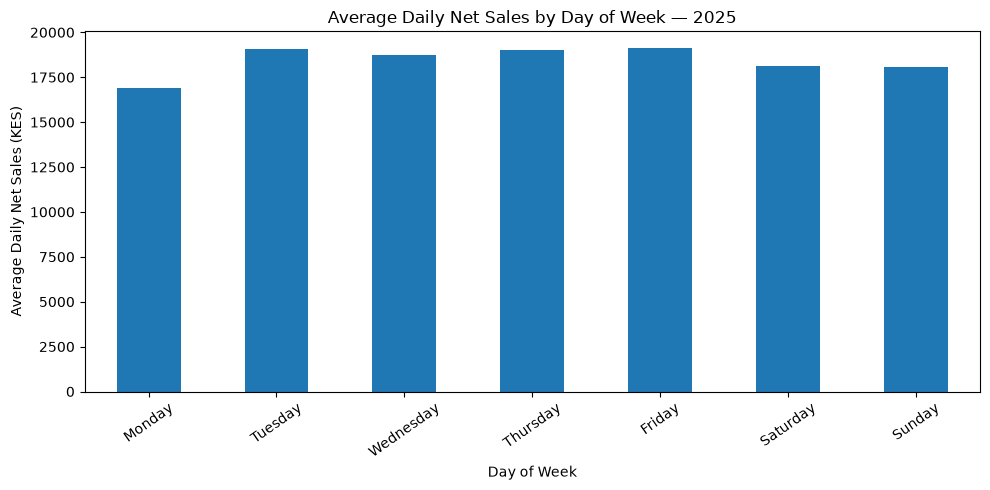

In [10]:

# Calculate average sales for each calendar day of the week
daily_totals = (
    sales.groupby(["transaction_date", "day_of_week"])["net_sales_kes"]
    .sum()
    .reset_index()
)

weekday_summary = (
    daily_totals.groupby("day_of_week")["net_sales_kes"]
    .agg(["mean", "sum", "count"])
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
)

weekday_summary.columns = [
    "average_daily_sales_kes",
    "total_sales_kes",
    "number_of_days"
]

display(weekday_summary)

plt.figure(figsize=(10, 5))
weekday_summary["average_daily_sales_kes"].plot(kind="bar")
plt.title("Average Daily Net Sales by Day of Week — 2025")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Net Sales (KES)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


### Finding 8: Average Daily Sales by Day of the Week

Friday recorded the highest average daily net sales in 2025, at KES 19,101.84, followed by Tuesday at KES 19,057.07 and Thursday at KES 19,009.25. Monday had the lowest average daily sales, at KES 16,891.06. Weekend averages were relatively similar, with Saturday at KES 18,152.48 and Sunday at KES 18,067.24. This pattern suggests that sales performance varies by day of the week, with Friday performing best on average and Monday performing weakest. Further investigation would be needed to determine the reasons behind these differences.

,month,month_name,average_daily_sales_kes,total_net_sales_kes,number_of_days
0,1,January,17184.338710,532714.50,31
1,2,February,17872.033929,500416.95,28
2,3,March,17724.274839,549452.52,31
3,4,April,19288.236667,578647.10,30
4,5,May,20457.881613,634194.33,31
5,6,June,18624.779000,558743.37,30
6,7,July,18623.594839,577331.44,31
7,8,August,18401.393871,570443.21,31
8,9,September,16774.319000,503229.57,30
9,10,October,19226.287097,596014.90,31


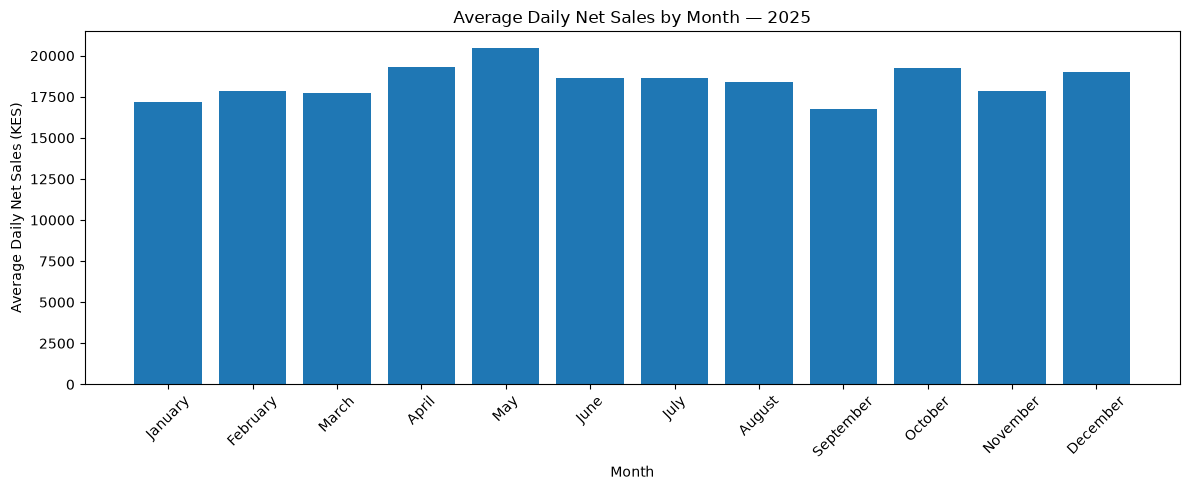

In [11]:

# Calculate daily sales first, then average them by month
sales["transaction_date"] = pd.to_datetime(sales["transaction_date"])

daily_monthly_sales = (
    sales.groupby("transaction_date")["net_sales_kes"]
    .sum()
    .reset_index()
)

daily_monthly_sales["month"] = (
    daily_monthly_sales["transaction_date"].dt.month
)

daily_monthly_sales["month_name"] = (
    daily_monthly_sales["transaction_date"].dt.month_name()
)

monthly_daily_summary = (
    daily_monthly_sales.groupby(["month", "month_name"])["net_sales_kes"]
    .agg(["mean", "sum", "count"])
    .reset_index()
    .sort_values("month")
)

monthly_daily_summary.columns = [
    "month", "month_name", "average_daily_sales_kes",
    "total_net_sales_kes", "number_of_days"
]

display(monthly_daily_summary)

plt.figure(figsize=(12, 5))
plt.bar(
    monthly_daily_summary["month_name"],
    monthly_daily_summary["average_daily_sales_kes"]
)
plt.title("Average Daily Net Sales by Month — 2025")
plt.xlabel("Month")
plt.ylabel("Average Daily Net Sales (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Finding 9: Average Daily Sales by Month

May recorded the highest average daily net sales in 2025, at KES 20,457.88, while September recorded the lowest, at KES 16,774.32. May's average was approximately 22% higher than September's. April, October and December also recorded relatively high average daily sales. These results indicate variation in sales performance across the year. However, because the dataset covers only 2025, further years of data would be required to confirm whether these patterns represent recurring seasonality.

Number of unique transactions: 5000

Transaction value summary:


count     5000.000000
mean      1345.257582
std       1390.497310
min         60.020000
25%        457.910000
50%        931.035000
75%       1726.505000
max      11953.920000
Name: transaction_value_kes, dtype: float64

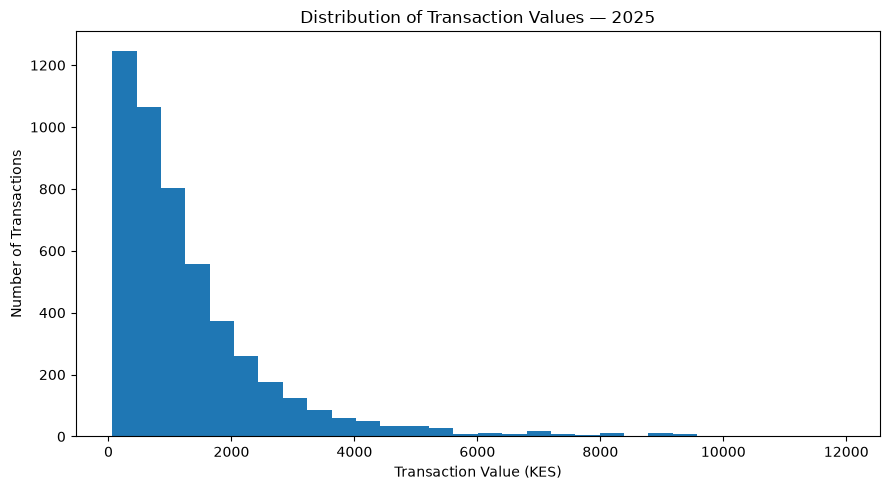

In [12]:

# One record per transaction to avoid counting multi-item transactions repeatedly
transaction_summary = (
    sales.groupby("transaction_id")
    .agg(
        transaction_value_kes=("net_sales_kes", "sum"),
        customer_id=("customer_id", "first"),
        transaction_date=("transaction_date", "first"),
        payment_method=("payment_method", "first")
    )
    .reset_index()
)

print("Number of unique transactions:", transaction_summary["transaction_id"].nunique())
print("\nTransaction value summary:")
display(transaction_summary["transaction_value_kes"].describe())

plt.figure(figsize=(9, 5))
plt.hist(
    transaction_summary["transaction_value_kes"],
    bins=30
)
plt.title("Distribution of Transaction Values — 2025")
plt.xlabel("Transaction Value (KES)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


### Finding 10: Distribution of Transaction Values

The dataset contains 5,000 unique transactions. The average transaction value was KES 1,345.26, while the median was KES 931.04. The histogram shows a right-skewed distribution, with most transactions concentrated at lower values and a smaller number of high-value transactions extending the upper tail. The maximum transaction value was KES 11,953.92. The difference between the mean and median suggests that high-value transactions influence the average. These transactions should be investigated before being classified as errors or unusual customer behaviour.

,payment_method,transactions,total_sales_kes,average_transaction_kes
0,M-Pesa,2862,3787626.33,1323.419403
1,Cash,1292,1782764.22,1379.848467
2,Debit/Credit Card,703,984471.83,1400.386671
3,Bank Transfer,143,171425.53,1198.779930


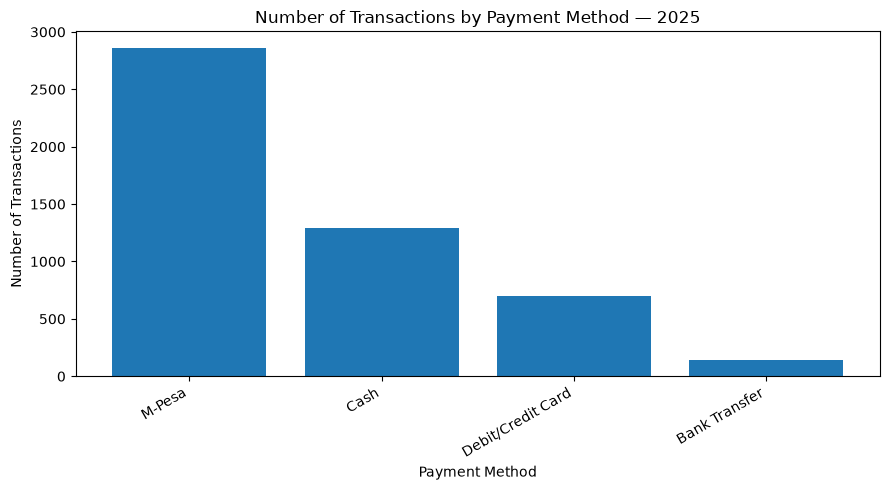

In [13]:

# Analyse payment methods at transaction level
payment_summary = (
    transaction_summary.groupby("payment_method")
    .agg(
        transactions=("transaction_id", "nunique"),
        total_sales_kes=("transaction_value_kes", "sum"),
        average_transaction_kes=("transaction_value_kes", "mean")
    )
    .sort_values("total_sales_kes", ascending=False)
    .reset_index()
)

display(payment_summary)

plt.figure(figsize=(9, 5))
plt.bar(
    payment_summary["payment_method"],
    payment_summary["transactions"]
)
plt.title("Number of Transactions by Payment Method — 2025")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### Finding 11: Payment Method Analysis

M-Pesa was the most frequently used payment method in 2025, accounting for 2,862 of 5,000 transactions (57.2%) and generating KES 3,787,626.33 in total net sales. Cash ranked second, with 1,292 transactions, followed by debit/credit cards with 703 transactions. Bank transfers were least common, with 143 transactions. Average transaction values were relatively close across payment methods, ranging from approximately KES 1,198.78 for bank transfers to KES 1,400.39 for cards. M-Pesa's leading contribution to total sales is therefore largely associated with its higher transaction volume.

Net sales by county and product category (KES):


product_category,Bakery,Beverages,Dairy & Chilled,Electronics & Accessories,Food & Pantry,Home Essentials,Household,Personal Care,Stationery
county,,,,,,,,,
Kiambu,11308.04,76242.68,101216.50,200561.30,207276.50,346210.23,94574.91,119634.24,55017.73
Kisumu,5504.42,59712.36,77657.14,115140.49,138015.04,159016.34,63208.02,77456.36,45082.96
Machakos,6947.17,73324.94,79224.66,119191.73,140821.21,152897.97,67852.86,74942.81,45120.41
Mombasa,11634.16,82283.60,92907.42,201561.94,178151.65,213997.31,84064.55,119799.55,55507.70
Nairobi,12857.11,106472.50,156079.16,304147.82,274697.68,319740.99,119814.75,149380.25,80623.16
Nakuru,8026.49,52071.65,54764.79,124135.20,137338.42,135754.69,53416.21,66825.00,41668.88
Nyeri,2686.94,28624.68,30960.86,92201.51,68821.51,76330.33,34969.92,55836.33,19500.43
Uasin Gishu,6192.47,33672.13,35521.19,76433.94,65973.78,58846.33,31826.69,37433.17,19574.05


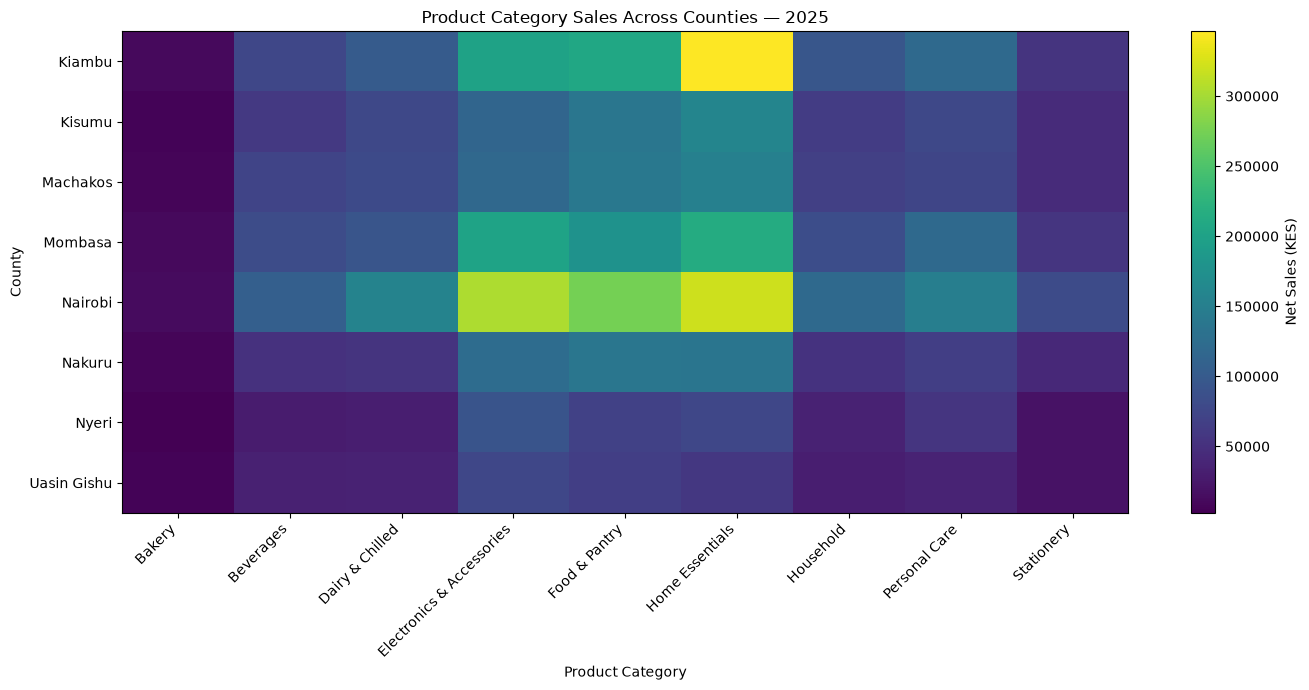


Top-selling category in each county:


,top_product_category
county,
Kiambu,Home Essentials
Kisumu,Home Essentials
Machakos,Home Essentials
Mombasa,Home Essentials
Nairobi,Home Essentials
Nakuru,Food & Pantry
Nyeri,Electronics & Accessories
Uasin Gishu,Electronics & Accessories


In [14]:

# Compare product category sales across counties
county_category_sales = (
    sales.pivot_table(
        index="county",
        columns="product_category",
        values="net_sales_kes",
        aggfunc="sum",
        fill_value=0
    )
)

print("Net sales by county and product category (KES):")
display(county_category_sales.round(2))

# Visualise the comparison as a heatmap
plt.figure(figsize=(14, 7))
plt.imshow(county_category_sales, aspect="auto")
plt.colorbar(label="Net Sales (KES)")

plt.xticks(
    range(len(county_category_sales.columns)),
    county_category_sales.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(county_category_sales.index)),
    county_category_sales.index
)

plt.title("Product Category Sales Across Counties — 2025")
plt.xlabel("Product Category")
plt.ylabel("County")
plt.tight_layout()
plt.show()

# Identify the top-selling category in each county
top_category_by_county = county_category_sales.idxmax(axis=1)

print("\nTop-selling category in each county:")
display(top_category_by_county.to_frame(name="top_product_category"))


### Finding 12: Product Category Sales Across Counties

The analysis identified differences in the highest-selling product categories across the eight counties. Home Essentials was the leading category in Kiambu, Kisumu, Machakos, Mombasa and Nairobi. Food & Pantry ranked first in Nakuru, while Electronics & Accessories led in Nyeri and Uasin Gishu. These results suggest that category performance varies by location. Jirani Mart could use this information to support county-level inventory planning and promotional decisions, while considering additional factors such as profit margins, stock availability and customer demand.

Top 10 Products by Net Sales:


,product_name,total_net_sales_kes,total_quantity
0,Cooking Gas Refill 6kg,1390679.82,973
1,Phone Charger,778097.51,831
2,USB Cable,455276.42,1018
3,Eggs Tray 30,436703.93,849
4,Shampoo 400ml,391569.31,939
5,Coffee 100g,307508.63,887
6,Rice 2kg,290243.57,919
7,Sugar 2kg,269658.47,876
8,School Exercise Books 10-pack,249419.37,840
9,Cooking Oil 1L,242011.50,870


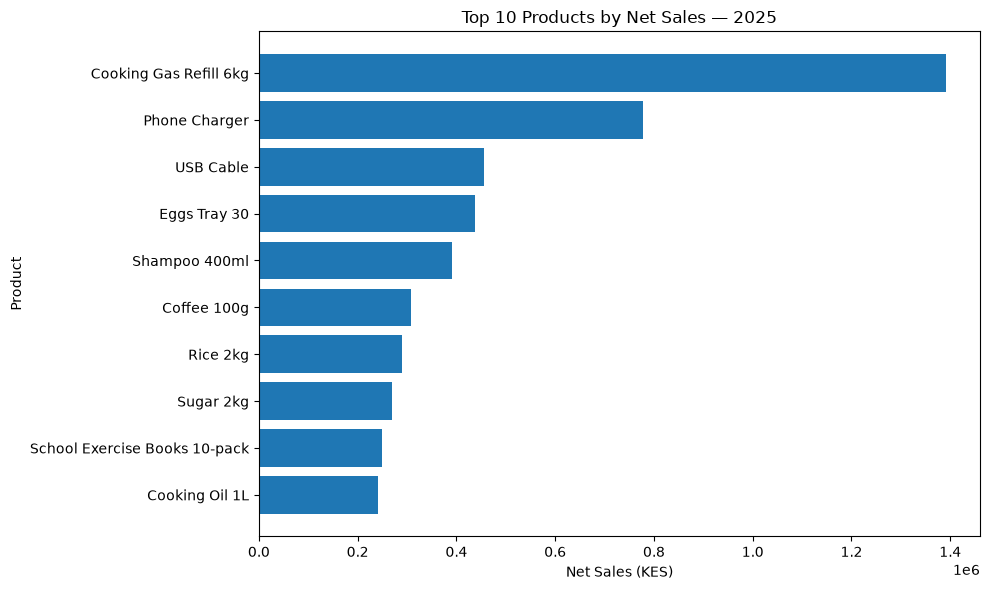

In [15]:

# Top 10 individual products by net sales
top_products = (
    sales.groupby("product_name")
    .agg(
        total_net_sales_kes=("net_sales_kes", "sum"),
        total_quantity=("quantity", "sum")
    )
    .sort_values("total_net_sales_kes", ascending=False)
    .head(10)
    .reset_index()
)

print("Top 10 Products by Net Sales:")
display(top_products)

# Plot the top 10 products
plt.figure(figsize=(10, 6))
plt.barh(
    top_products["product_name"][::-1],
    top_products["total_net_sales_kes"][::-1]
)
plt.title("Top 10 Products by Net Sales — 2025")
plt.xlabel("Net Sales (KES)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### Finding 13: Top 10 Products by Net Sales

Cooking Gas Refill 6kg was the highest-revenue individual product in 2025, generating KES 1,390,679.82 in net sales from 973 units sold. Phone Charger ranked second, generating KES 778,097.51 from 831 units, followed by USB Cable at KES 455,276.42 from 1,018 units. USB Cable recorded the highest quantity sold among the top 10 products, while Cooking Gas Refill generated the highest revenue. These findings show that sales volume and revenue contribution are not necessarily the same. Jirani Mart could use these results to prioritise stock monitoring while also considering profit margins and replenishment costs.